# 01 - Data Preparation & Baseline Evaluation

**Goal:** prepare the Text-to-SQL dataset (`b-mc2/sql-create-context`), split it without schema leakage,
analyze the query-complexity distribution, and measure the **base model before fine-tuning** (baseline).

**Google Colab:** *Runtime -> Change runtime type -> T4 GPU*. The first cell looks for the project zip (Google Drive, or an upload dialog). Run the cells from top to bottom (*Runtime -> Run all*). Save the notebook together with its outputs: *File -> Download -> Download .ipynb*.
**Kaggle:** Accelerator = T4 GPU (not P100), Internet = On, project added as a Dataset (*Add Input*).
Do not pick the P100 GPU (not supported by Unsloth).
Cells marked **[GPU]** need a GPU; all other cells run on CPU only.

In [ ]:
import glob
import os
import sys
from pathlib import Path

try:                                    # detect Google Colab
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

USE_DRIVE = True   # Colab: keep data/results on Google Drive so they survive a disconnected session


def find_project_root():
    """Find the project folder (the one containing src/sql_utils.py): working dir, Kaggle Dataset, or a Colab upload."""
    candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
    candidates += [Path(p).parent.parent for p in glob.glob("/kaggle/input/**/src/sql_utils.py", recursive=True)]
    candidates += [Path(p).parent.parent for p in glob.glob("/content/*/src/sql_utils.py") + glob.glob("/content/*/*/src/sql_utils.py")]
    for c in candidates:
        if (c / "src" / "sql_utils.py").exists():
            return c
    return None


ROOT = find_project_root()
if ROOT is None and IN_COLAB:
    import zipfile
    ZIP_NAME = "Text2SQL_Dwi-Cahyo-Mariyanto.zip"
    # Easiest: put the project zip ONCE in Google Drive (My Drive); this cell finds it by itself, no upload dialog.
    if USE_DRIVE:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            for z in (Path("/content/drive/MyDrive") / ZIP_NAME, Path("/content/drive/MyDrive/Text2SQL") / ZIP_NAME):
                if z.exists():
                    zipfile.ZipFile(z).extractall("/content")
                    print("Project loaded from Google Drive:", z)
                    break
        except Exception as e:                      # fine: fall back to manual upload
            print("Google Drive not used:", type(e).__name__)
        ROOT = find_project_root()
    if ROOT is None:                                # fallback: upload the zip from your computer
        from google.colab import files
        print("Select the file", ZIP_NAME, "from your computer ...")
        for name in files.upload():
            if name.lower().endswith(".zip"):
                zipfile.ZipFile(name).extractall("/content")
        ROOT = find_project_root()
if ROOT is None:
    raise FileNotFoundError(
        "Project folder not found. Colab: run this cell again and upload the project zip. "
        "Kaggle: upload the zip as a Dataset, then 'Add Input'."
    )

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # use a single GPU (safe on T4 x2)
if IN_COLAB and USE_DRIVE:
    try:
        if not os.path.ismount("/content/drive"):
            from google.colab import drive
            drive.mount("/content/drive")
        os.environ["T2S_WORK_DIR"] = "/content/drive/MyDrive/Text2SQL_Dwi-Cahyo-Mariyanto"
    except Exception as e:                          # fine: results are kept locally in the Colab session
        print("Google Drive not mounted, results are kept locally in this session:", type(e).__name__)
for sub in ("src", "Fine-tuning_submission", "Evaluation_submission", "Interface_submission"):
    sys.path.insert(0, str(ROOT / sub))
print("Project root:", ROOT)
if IN_COLAB:
    import torch
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT ACTIVE -> Runtime > Change runtime type > T4 GPU")

Mounted at /content/drive
Select the file Text2SQL_Dwi-Cahyo-Mariyanto.zip from your computer ...


Saving Text2SQL_Dwi-Cahyo-Mariyanto-final.zip to Text2SQL_Dwi-Cahyo-Mariyanto-final (1).zip
Project root: /content/Text2SQL_Dwi-Cahyo-Mariyanto
GPU: Tesla T4


## 1. Installation & configuration
All parameters live in one place (the cell below).

In [ ]:
%pip install -q unsloth  # [Kaggle/Colab] skip if already installed

In [ ]:
DATA_CONFIG = {
    "dataset_name": "b-mc2/sql-create-context",
    "seed": 42,
    "n_train": 5000,
    "n_val": 200,
    "n_test": 300,
    "group_fracs": (0.90, 0.05, 0.05),   # SCHEMA proportions for train/val/test
    "max_chars_question": 300,
    "max_chars_context": 1200,
    "max_chars_answer": 500,
}
EVAL_CONFIG = {
    "base_model": "unsloth/Qwen2.5-Coder-3B-Instruct-bnb-4bit",
    "max_seq_length": 512,
    "batch_size": 16,
    "max_new_tokens": 128,
}

## 2. Load, clean, and split the data
- Drop empty, overly long, and duplicate examples.
- **Split by schema (`context`)** so the same schema never appears in both train and test (prevents leakage).
- Question+SQL pairs identical to training data are removed from val/test.

In [ ]:
import json
from data_prep import prepare_data
from eval_utils import get_work_dir

WORK = get_work_dir()
RES_DIR = WORK / "results"
RES_DIR.mkdir(parents=True, exist_ok=True)

splits, stats = prepare_data(DATA_CONFIG, WORK / "data")
print(json.dumps(stats["cleaning"], indent=2))
print("Schema overlap between splits (must be 0):", stats["splits"]["schema_overlap"])

README.md:   0%|          | 0.00/4.43k [00:00<?, ?B/s]

sql_create_context_v4.json: reconstructing file:   0%|          |  0.00B / 21.8MB            

sql_create_context_v4.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/78577 [00:00<?, ? examples/s]

{
  "raw": 78577,
  "removed_empty": 0,
  "removed_too_long": 2,
  "removed_duplicates": 3,
  "clean": 78572
}
Schema overlap between splits (must be 0): {'train_val': 0, 'train_test': 0, 'val_test': 0}


## 3. Query-complexity distribution
Categories: `simple`, `aggregation` (COUNT/SUM/GROUP BY/...), `join`, `nested` (subquery/UNION/etc.).

split,test,train,val
category,,,
simple,217,3425,137
aggregation,79,1435,59
join,4,89,3
nested,0,51,1


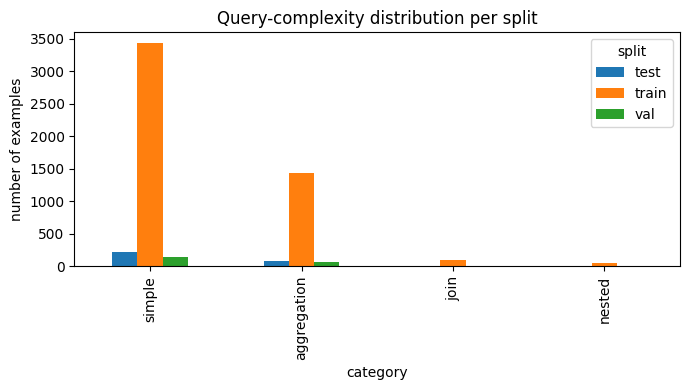

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sql_utils import CATEGORIES

rows = [
    {"split": s, "category": c, "count": stats["splits"][s]["category_counts"][c]}
    for s in ("train", "val", "test") for c in CATEGORIES
]
df = pd.DataFrame(rows).pivot(index="category", columns="split", values="count").loc[CATEGORIES]
display(df)
ax = df.plot(kind="bar", figsize=(7, 4), title="Query-complexity distribution per split")
ax.set_ylabel("number of examples")
plt.tight_layout()
plt.savefig(RES_DIR / "complexity_distribution.png", dpi=150)
plt.show()

In [ ]:
# Average text length (characters) per split
display(pd.DataFrame({s: {k: v for k, v in stats["splits"][s].items() if k.startswith("avg")} for s in ("train", "val", "test")}))

# Sample data
from eval_utils import load_jsonl
train = load_jsonl(WORK / "data" / "train.jsonl")
for r in train[:3]:
    print("Q:", r["question"]); print("SCHEMA:", r["context"]); print("SQL:", r["answer"], f"[{r['category']}]\n")

,train,val,test
avg_chars_question,60.6,63.3,60.0
avg_chars_context,71.5,71.9,70.7
avg_chars_answer,76.4,74.7,74.8


Q: What is Tournament, when Margin is Victory of 6 Strokes?
SCHEMA: CREATE TABLE table_name_30 (tournament VARCHAR, margin_of_victory VARCHAR)
SQL: SELECT tournament FROM table_name_30 WHERE margin_of_victory = "6 strokes" [simple]

Q: Which 1st prize ($) has a Winner of scott simpson (7)?
SCHEMA: CREATE TABLE table_name_21 (winner VARCHAR)
SQL: SELECT SUM(1 AS st_prize___) AS $__ FROM table_name_21 WHERE winner = "scott simpson (7)" [aggregation]

Q: What is the visiting team that has a home team related to footscray?
SCHEMA: CREATE TABLE table_name_24 (away_team VARCHAR, home_team VARCHAR)
SQL: SELECT away_team FROM table_name_24 WHERE home_team = "footscray" [simple]



## 4. Baseline: base model without fine-tuning **[GPU]**
The base model gets **exactly the same** prompt used in training and inference
(`src/prompt_utils.py`). Two main metrics:
- **Exact match** (normalized SQL identical to the reference), and
- **Execution match** (same execution result on a SQLite database with synthetic data matching the schema).

In [ ]:
from eval_utils import evaluate_records, generate_sql_batch, get_hf_token, load_for_inference, save_jsonl, write_metrics

test = load_jsonl(WORK / "data" / "test.jsonl")
model, tokenizer = load_for_inference(EVAL_CONFIG["base_model"], EVAL_CONFIG["max_seq_length"], token=get_hf_token())
preds = generate_sql_batch(model, tokenizer, test, EVAL_CONFIG["batch_size"], EVAL_CONFIG["max_new_tokens"])
records = [dict(r, pred=p) for r, p in zip(test, preds)]

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1121 07:53:11.812000 10116 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1121 07:53:11.907000 10116 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.9: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

In [ ]:
metrics_base = evaluate_records(records)
write_metrics(metrics_base, RES_DIR / "metrics_baseline.json")
save_jsonl(records, RES_DIR / "baseline_predictions.jsonl")
print(json.dumps({k: v for k, v in metrics_base.items() if k != "by_category"}, indent=2))
display(pd.DataFrame(metrics_base["by_category"]).T)

{
  "n": 300,
  "exact_match": 0.4967,
  "execution_match": 0.4662,
  "execution_match_nonempty": 0.4556,
  "n_gold_executable": 296,
  "n_gold_nonempty": 270,
  "pred_error_rate": 0.0405
}


,n,exact_match,execution_match,execution_match_nonempty,n_gold_executable,n_gold_nonempty,pred_error_rate
simple,217.0,0.5714,0.4419,0.4263,215.0,190.0,0.0419
aggregation,79.0,0.3165,0.5065,0.5065,77.0,77.0,0.0390
join,4.0,0.0000,1.0000,1.0000,4.0,3.0,0.0000


In [ ]:
for r in records[:5]:
    print("Q   :", r["question"]); print("GOLD:", r["answer"]); print("PRED:", r["pred"], "| exec_match =", r["exec_match"], "\n")

import gc, torch
del model, tokenizer
gc.collect(); torch.cuda.empty_cache()   # free the GPU before the next notebook

Q   : How many cities are there in state "Colorado"?
GOLD: SELECT COUNT(*) FROM addresses WHERE state_province_county = "Colorado"
PRED: SELECT COUNT(*) FROM addresses WHERE state_province_county = 'Colorado' | exec_match = True 

Q   : What is the duration that has 3 for appearances, and james garret as the character?
GOLD: SELECT duration FROM table_name_20 WHERE appearances = "3" AND character = "james garret"
PRED: SELECT duration FROM table_name_20 WHERE appearances = '3' AND character = 'james garret' | exec_match = True 

Q   : Tell me the sum of Grid for giancarlo fisichella
GOLD: SELECT SUM(grid) FROM table_name_84 WHERE driver = "giancarlo fisichella"
PRED: SELECT SUM(grid) FROM table_name_84 WHERE driver = 'Giancarlo Fisichella' | exec_match = False 

Q   : What general classification has 4 as the stage?
GOLD: SELECT general_classification FROM table_name_96 WHERE stage = "4"
PRED: SELECT general_classification FROM table_name_96 WHERE stage = '4' | exec_match = True 

Q   :

## Save results
In Colab, a zip archive is downloaded to your computer automatically; on Kaggle it appears in the Output tab after *Save Version*.

In [ ]:
from eval_utils import export_results

export_results(RES_DIR)

Results archive: /content/drive/MyDrive/Text2SQL_Dwi-Cahyo-Mariyanto/outputs/text2sql_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/drive/MyDrive/Text2SQL_Dwi-Cahyo-Mariyanto/outputs/text2sql_results.zip')

## 5. Summary
- Clean data, schema-leak-free split, documented complexity distribution.
- Baseline metrics are stored in `outputs/results/metrics_baseline.json` and used as the comparison in notebook 03.
- **Next:** `02_finetune_qlora.ipynb`.